# 6. Direct Carbon-Box Coefficient Inference, Fisher Identifiability & Reservoir Selection

In `ticktack 1.x`, every carbon box model (`Guttler15`, `Brehm21`, `Miyake17`, `Buntain18`) was compiled once from static reservoir turnover tables into a frozen ODE matrix (`CarbonBoxModel.compile()`), making direct Bayesian inference of reservoir transfer coefficients impossible without rebuilding the numerical integrator at every random-walk `emcee` step.

In `ticktack 2.0`, every `CarbonBoxModel` (`BalancedCBM`, `ReversibleCBM`, `OpenCBM`, and canonical `EffectiveCBM`) is a differentiable Equinox PyTree whose exact steady-state Kirchhoff mass balance, symmetric detailed-balance eigendecomposition (`jax.scipy.linalg.eigh`), and modal LTI propagation differentiate end to end under `jax.grad`. This tutorial quantifies which carbon-cycle combinations tree-ring $\Delta^{14}\mathrm{C}$ data actually constrain (`cbm_fisher_spectrum`), recovers box-model transfer coefficients jointly with 774 CE spike parameters (`fit_map` + `sample_nuts`), and selects reservoir complexity $K$ via `BlackJAX` adaptive tempered `sample_smc`.

In [1]:
import math, time, jax, jax.numpy as jnp, numpy as np
from tqdm.auto import tqdm
import ticktack as tt
cedar = tt.TreeRingSeries.from_csv("notebooks/miyake12.csv", hemisphere="north", growth_season="april-september", name="Miyake12_Cedar")
ds_cedar, spike0 = tt.Dataset(cedar, name="Miyake12_CBM"), tt.MiyakeSpike(774.5, 0.35, 6.5, profile="boxcar")
psi0 = {"spike": spike0, "offsets": jnp.zeros(ds_cedar.n_series)}
fwd = lambda cbm_v, psi: tt.RadiocarbonModel(cbm_v, tt.SteadyProduction() + psi["spike"]).predict_d14c(ds_cedar, offsets=psi["offsets"])
cbm_b21, cbm_g15 = tt.load_preset("Brehm21", kind="balanced"), tt.load_preset("Guttler15", kind="balanced")
spec_b21 = tt.cbm_fisher_spectrum(fwd, cbm_b21, ds_cedar.sigma_flat, psi_nuisance=psi0, prior_cbm_sd=0.35)
spec_g15 = tt.cbm_fisher_spectrum(fwd, cbm_g15, ds_cedar.sigma_flat, psi_nuisance=psi0, prior_cbm_sd=0.35)
jax.clear_caches()
t0 = time.perf_counter()
specs_eff = {k: tt.cbm_fisher_spectrum(fwd, tt.EffectiveCBM(K=k), ds_cedar.sigma_flat, psi_nuisance=psi0, prior_cbm_sd=0.35) for k in (2, 3, 4)}
dt_f_cold, t1 = time.perf_counter() - t0, time.perf_counter()
_ = tt.cbm_fisher_spectrum(fwd, tt.EffectiveCBM(K=3), ds_cedar.sigma_flat, psi_nuisance=psi0, prior_cbm_sd=0.35)
print(f"Fisher d_eff (Miyake12_Cedar): Brehm21({cbm_b21.log_rates_free.size} rates)={float(spec_b21.d_eff):.2f} ({float(spec_b21.info_bits):.2f} bits), Guttler15({cbm_g15.log_rates_free.size})={float(spec_g15.d_eff):.2f}\nEffectiveCBM K=2:{float(specs_eff[2].d_eff):.2f}, K=3:{float(specs_eff[3].d_eff):.2f}, K=4:{float(specs_eff[4].d_eff):.2f} | cold={dt_f_cold*1e3:.0f} ms, warm={(time.perf_counter()-t1)*1e3:.1f} ms (v1: N/A)")

Fisher d_eff (Miyake12_Cedar): Brehm21(56 rates)=0.75 (0.86 bits), Guttler15(24)=0.86
EffectiveCBM K=2:0.52, K=3:1.03, K=4:0.99 | cold=17342 ms, warm=41.3 ms (v1: N/A)


## Laplace-Relaxation Ill-Conditioning & Information Saturation

Decadal tree-ring radiocarbon observations sample a diffusive Laplace transform of reservoir residence times whose prior-whitened Fisher eigenvalues decay exponentially with mode index, paralleling the multi-exponential identifiability hierarchy analysed by [Langker et al. (2026)](https://arxiv.org/abs/2610.41092v1). Even after [Schur complement](https://en.wikipedia.org/wiki/Schur_complement) marginalization over the spike and ambient baseline offset (which projects out nuisance parameter covariances from the joint Fisher block and treats global carbon mass analytically as a zero-Fisher gauge mode), only a couple of collective exchange combinations rise above or approach the unit signal-to-prior threshold on the 28-ring `Miyake12_Cedar` series in `Brehm21` and `Guttler15` – explaining why canonical `EffectiveCBM(K=2–3)` captures virtually all identifiable carbon-cycle dynamics.

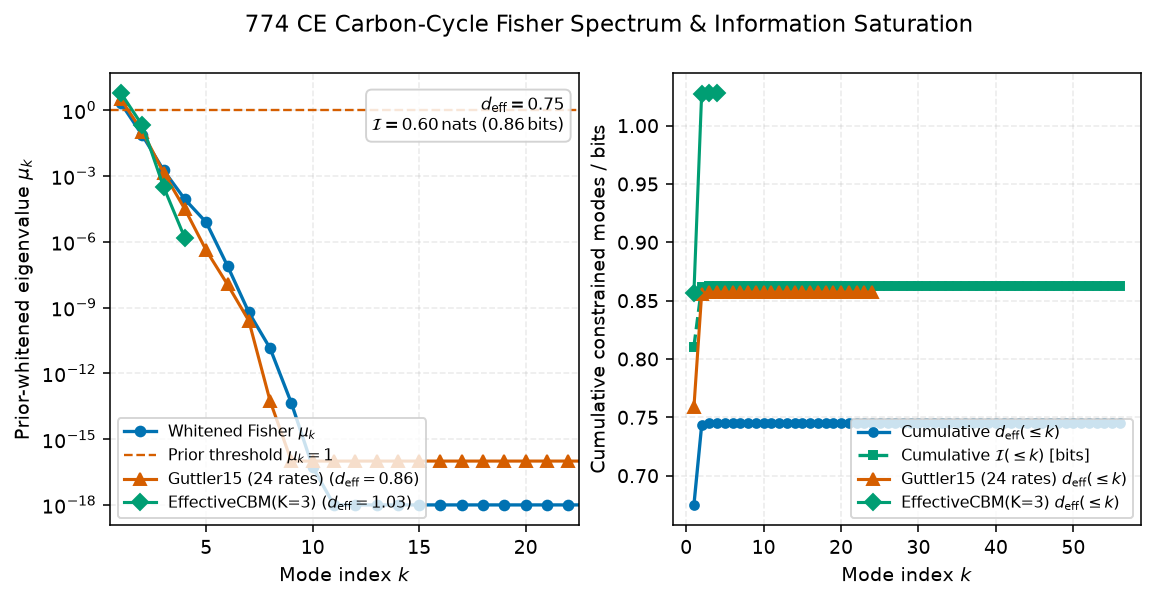

In [2]:
fig_f, axes_f = tt.plot_fisher_spectrum(spec_b21, title="774 CE Carbon-Cycle Fisher Spectrum & Information Saturation")
for label, sp, col, mk in [(f"Guttler15 ({cbm_g15.log_rates_free.size} rates)", spec_g15, "#D55E00", "^"), ("EffectiveCBM(K=3)", specs_eff[3], "#009E73", "D")]:
    mu = np.maximum(np.asarray(sp.eigenvalues), 1e-16)
    idx = np.arange(1, mu.size + 1)
    axes_f[0].semilogy(idx, mu, marker=mk, lw=1.6, color=col, label=f"{label} ($d_{{\\mathrm{{eff}}}}={float(sp.d_eff):.2f}$)")
    axes_f[1].plot(idx, np.cumsum(mu / (1.0 + mu)), marker=mk, lw=1.6, color=col, label=f"{label} $d_{{\\mathrm{{eff}}}}(\\leq k)$")
axes_f[0].set_xlim(0.5, 22.5)
axes_f[0].legend(loc="lower left", frameon=True, fontsize=8.0)
axes_f[1].legend(loc="lower right", frameon=True, fontsize=8.0)

## Direct Joint CBM + Spike Recovery (`EffectiveCBM` & Kirchhoff `ReversibleCBM`)

Because detailed-balance `ReversibleCBM` and `EffectiveCBM` symmetrize the transport generator via steady-state reservoir masses before calling `jax.scipy.linalg.eigh`, reverse-mode gradients through the eigensystem are exact and free of non-normal `eig` singularities. Below we jointly fit both the 4-box Kirchhoff flow-balanced `Miyake17` `ReversibleCBM` symmetric fluxes (`cbm.log_sym_fluxes`, preserving zero Kirchhoff mass-balance residual identically) and the 4-parameter `EffectiveCBM(K=3)` exchange rates alongside the 774 CE spike on `Miyake12_Cedar` via `fit_map` and `sample_nuts`.

In [3]:
jax.clear_caches()
cfg_c, t_fine = tt.LinearMarginalConfig(offset_mode="shared"), jnp.linspace(759.5, 788.5, 291)
cbm3, cbm_rev = tt.EffectiveCBM(K=3), tt.load_preset("Miyake17", kind="reversible", miyake17_closure="closed_shallow")
sp_specs = [tt.ParamSpec("production.spike.t_start", "sigmoid", 0.0, 1.2, low=773.5, high=776.0), tt.ParamSpec("production.spike.fluence", "exp", math.log(6.5), 0.5)]
eff_cbm_specs = lambda c: [tt.ParamSpec("cbm.log_k_strat_to_trop", "identity", float(c.log_k_strat_to_trop), 0.35), tt.ParamSpec("cbm.log_k_trop_to_strat", "identity", float(c.log_k_trop_to_strat), 0.35), tt.ParamSpec("cbm.log_k_trop_to_sinks", "identity", c.log_k_trop_to_sinks, 0.35), tt.ParamSpec("cbm.sink_tau_params", "identity", c.sink_tau_params, 0.50)]
m_eff = tt.RadiocarbonModel(cbm3, tt.ProductionSum(steady=tt.SteadyProduction(), spike=spike0))
m_rev = tt.RadiocarbonModel(cbm_rev, tt.ProductionSum(steady=tt.SteadyProduction(), spike=spike0))
ps_eff, ps_rev = tt.ParameterSpace(m_eff, eff_cbm_specs(cbm3) + sp_specs), tt.ParameterSpace(m_rev, [tt.ParamSpec("cbm.log_sym_fluxes", "identity", cbm_rev.log_sym_fluxes, 0.35)] + sp_specs)
map_rev = tt.fit_map(m_rev, ds_cedar, ps_rev, cfg_c, max_steps=120, rng_key=jax.random.PRNGKey(600))
t0 = time.perf_counter()
map_eff = tt.fit_map(m_eff, ds_cedar, ps_eff, cfg_c, max_steps=120, rng_key=jax.random.PRNGKey(601))
idata_eff = tt.sample_nuts(map_eff.model, ds_cedar, ps_eff, cfg_c, num_warmup=150, num_samples=250, num_chains=2, max_tree_depth=6, init_map=False, t_fine=t_fine, rng_key=jax.random.PRNGKey(602))
dt_joint_cold, t1 = time.perf_counter() - t0, time.perf_counter()
map_w = tt.fit_map(m_eff, ds_cedar, ps_eff, cfg_c, max_steps=120, rng_key=jax.random.PRNGKey(601))
_ = tt.sample_nuts(map_w.model, ds_cedar, ps_eff, cfg_c, num_warmup=150, num_samples=250, num_chains=2, max_tree_depth=6, init_map=False, t_fine=t_fine, rng_key=jax.random.PRNGKey(603))
print(f"EffectiveCBM(K=3) NUTS: tau_strat={(1.0/np.exp(idata_eff.posterior['cbm__log_k_strat_to_trop'].values)).mean():.2f}+/-{(1.0/np.exp(idata_eff.posterior['cbm__log_k_strat_to_trop'].values)).std():.2f} yr, sink_tau1={float(map_eff.model.cbm.sink_timescales()[0]):.1f} yr, fluence={idata_eff.posterior['production__spike__fluence'].values.mean():.2f}+/-{idata_eff.posterior['production__spike__fluence'].values.std():.2f}\nReversibleCBM(Miyake17) MAP fluxes={np.round(np.exp(np.asarray(map_rev.model.cbm.log_sym_fluxes)), 1)} GtC/yr (max |Kirchhoff|={float(jnp.max(jnp.abs(map_rev.model.cbm.kirchhoff_residual()))):.1e})\nJoint CBM+spike MAP+NUTS (v1: static CBM only): cold={dt_joint_cold:.2f} s, warm={time.perf_counter()-t1:.2f} s")

EffectiveCBM(K=3) NUTS: tau_strat=2.23+/-0.88 yr, sink_tau1=4.8 yr, fluence=6.68+/-1.35
ReversibleCBM(Miyake17) MAP fluxes=[73.7 40.9 19.6] GtC/yr (max |Kirchhoff|=0.0e+00)
Joint CBM+spike MAP+NUTS (v1: static CBM only): cold=13.45 s, warm=3.36 s


## Thermodynamic Reservoir Selection Across $K = 1, 2, 3$ (`sample_smc`)

To test how many effective carbon reservoirs the 28-ring `Miyake12_Cedar` series warrants under Bayesian Occam's razor, we run `BlackJAX` adaptive tempered Sequential Monte Carlo (`sample_smc`, using multinomial resampling and [Lee & Whiteley 2018](https://doi.org/10.1093/biomet/asy028) ancestral-lineage log-evidence uncertainties) across a single well-mixed troposphere (`K = 1`, `OpenCBM`), a coupled stratosphere–troposphere 2-box model (`K = 2`), and the 3-box stratosphere–troposphere–sink hierarchy (`K = 3`).

In [4]:
jax.clear_caches()
cbm_k1 = tt.OpenCBM(tt.Topology(["Troposphere"], [], []), jnp.zeros(0), math.log(501.5), jnp.array([math.log(0.088)]), open_box_indices=[0])
smc_res, smc_cold = {}, {}
for k, cbm_k in tqdm({1: cbm_k1, 2: tt.EffectiveCBM(K=2), 3: tt.EffectiveCBM(K=3)}.items(), desc="SMC reservoir sweep", leave=False):
    m_k = tt.RadiocarbonModel(cbm_k, tt.ProductionSum(steady=tt.SteadyProduction(), spike=spike0))
    c_sp = [tt.ParamSpec("cbm.log_sink_rates", "identity", float(cbm_k.log_sink_rates[0]), 0.35)] if k == 1 else eff_cbm_specs(cbm_k)
    t0 = time.perf_counter()
    smc_res[k] = tt.sample_smc(m_k, ds_cedar, tt.ParameterSpace(m_k, c_sp + sp_specs), cfg_c, num_particles=120, num_mcmc_steps=4, rng_key=jax.random.PRNGKey(610 + k))
    jax.block_until_ready(smc_res[k].log_evidence)
    smc_cold[k] = time.perf_counter() - t0
t1 = time.perf_counter()
smc_w = tt.sample_smc(m_eff, ds_cedar, ps_eff, cfg_c, num_particles=120, num_mcmc_steps=4, rng_key=jax.random.PRNGKey(620))
jax.block_until_ready(smc_w.log_evidence)
best_z, dt_smc_w = max(float(r.log_evidence) for r in smc_res.values()), time.perf_counter() - t1
print("\n".join(f"K={k} ({r.particles.shape[1]}D): ln Z = {float(r.log_evidence):.2f} +/- {float(r.log_evidence_err):.2f} (Delta={float(r.log_evidence)-best_z:+.2f}, cold={smc_cold[k]:.2f} s)" for k, r in smc_res.items()) + f"\nK=3 SMC warm={dt_smc_w:.2f} s (v1: no evidence or CBM sampling)")

K=1 (3D): ln Z = -73.55 +/- 0.17 (Delta=-10.35, cold=11.00 s)
K=2 (4D): ln Z = -71.12 +/- 0.34 (Delta=-7.92, cold=5.76 s)
K=3 (6D): ln Z = -63.20 +/- 0.17 (Delta=+0.00, cold=5.59 s)
K=3 SMC warm=0.05 s (v1: no evidence or CBM sampling)


## Joint Carbon-Cycle + Spike Posterior $\Delta^{14}\mathrm{C}(t)$ Trajectory & Pulls

Propagating the joint `EffectiveCBM(K=3)` + spike NUTS posterior draws into tropospheric $\Delta^{14}\mathrm{C}(t)$ (`plot_d14c_fit` with `show_residuals=True`) illustrates how inferring stratospheric residence time and decadal sink uptake alongside the cosmic-ray fluence reproduces both the sharp 774–775 CE rise and post-spike relaxation with unit-normal standardized pulls $(d - m)/\sigma$.

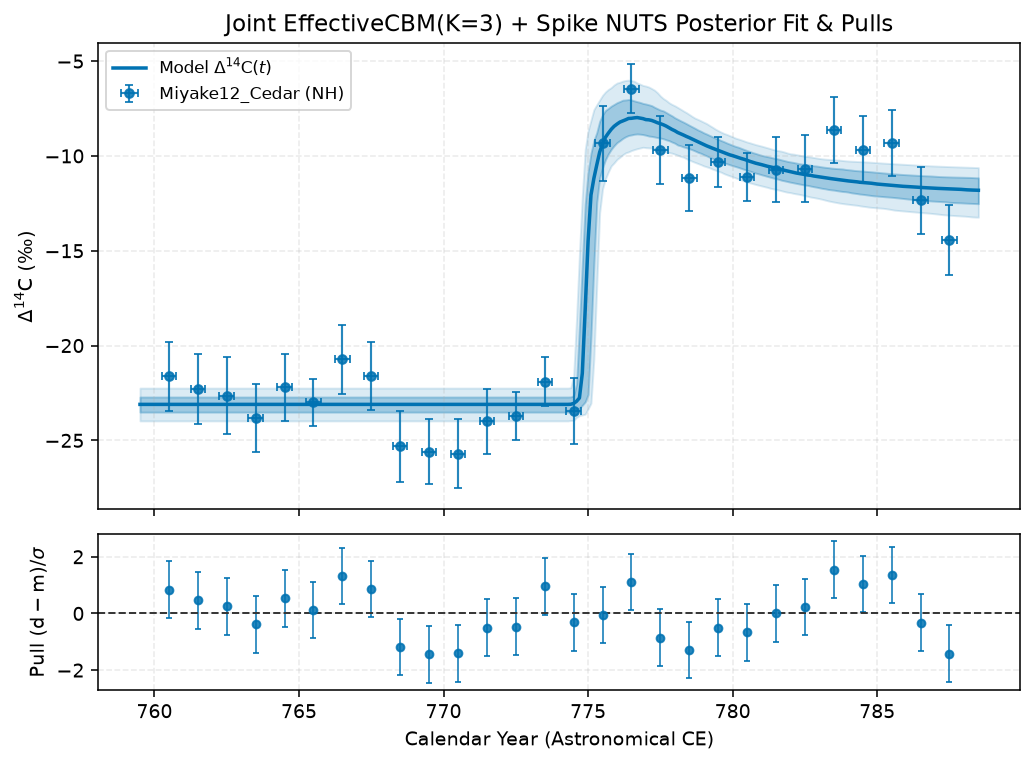

In [5]:
d14c_draws = idata_eff.posterior_predictive["d14c_fine"].values.reshape(-1, t_fine.size)
lp_eff = tt.linear_posterior(map_eff.model, ds_cedar, cfg_c, t_fine=t_fine)
fig_fit, axes_fit = tt.plot_d14c_fit(
    ds_cedar,
    t_fine=t_fine,
    d14c_pred=d14c_draws,
    ring_pred=lp_eff.ring_pred_mean,
    show_residuals=True,
    title="Joint EffectiveCBM(K=3) + Spike NUTS Posterior Fit & Pulls",
)

## One-to-One Observed vs Predicted Calibration

Inspecting `plot_data_model_correlation` on the joint carbon-box + spike fit confirms unbiased `1:1` calibration across the full `~20‰` excursion with well-calibrated $\chi^2 / N_{\mathrm{obs}}$ and inverse-variance weighted RMS pull.

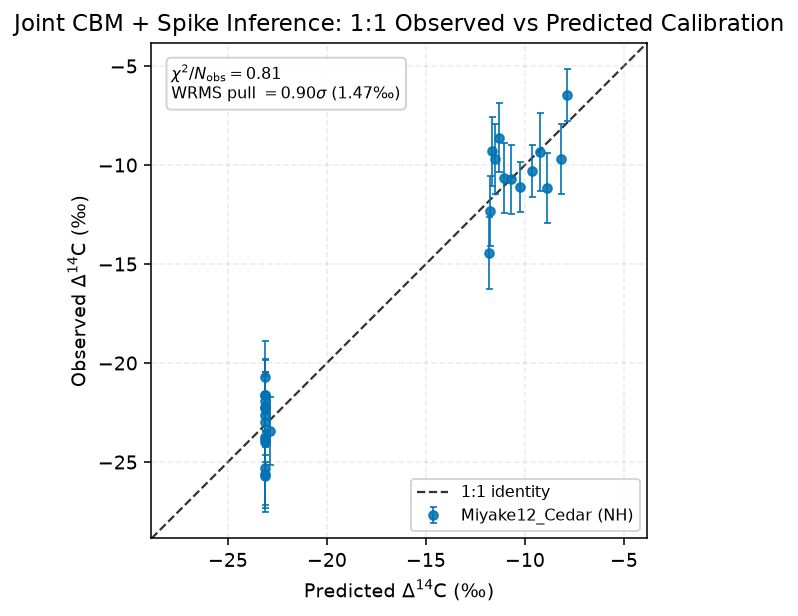

In [6]:
fig_corr, ax_corr = tt.plot_data_model_correlation(
    ds_cedar,
    lp_eff.ring_pred_mean,
    title="Joint CBM + Spike Inference: 1:1 Observed vs Predicted Calibration",
)

Differentiable `CarbonBoxModel` PyTrees, Schur-marginalized `cbm_fisher_spectrum` diagnostics, symmetric detailed-balance `eigh` autodiff, and `BlackJAX` tempered SMC (`sample_smc`) turn reservoir transport coefficients from fixed `v1` lookup tables into first-class, evidence-tested parameters of radiocarbon inference.